In [ ]:
!pip install openpyxl -q

import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

print("pandas:", pd.__version__)
print("numpy :", np.__version__)

pandas: 2.2.3
numpy : 2.1.3


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving result_2026-10-27-12-29-45.xls to result_2026-10-27-12-29-45.xls


In [ ]:
FILENAME = "result_2026-10-27-12-29-45.xls"
try:
    df = pd.read_excel(FILENAME, engine="openpyxl")
except Exception as e:
    print("openpyxl failed:", e)
    print("Trying with xlrd (legacy .xls)...")
    !pip install xlrd -q
    df = pd.read_excel(FILENAME, engine="xlrd")

print("Shape:", df.shape)
print("\nColumns:")
for col in df.columns:
    print("  -", col)
print("\nFirst 3 rows (truncated):")
pd.set_option("display.max_colwidth", 80)
print(df.head(3).to_string())

openpyxl failed: File is not a zip file
Trying with xlrd (legacy .xls)...
Shape: (831, 12)

Columns:
  - run_id
  - router_id
  - timestamp_phase1
  - timestamp_phase3
  - tier
  - state_before
  - state_after
  - command_sent
  - recovery_time_ms
  - reward_score
  - created_at
  - updated_at

First 3 rows (truncated):
                 run_id     router_id  timestamp_phase1  timestamp_phase3         tier                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                

In [ ]:
import json
import numpy as np
import pandas as pd

def safe_parse(x):
    """Parse a JSON string, return None if empty or invalid."""
    if pd.isna(x) or x is None:
        return None
    if isinstance(x, dict):
        return x
    try:
        return json.loads(x)
    except (json.JSONDecodeError, TypeError):
        return None

# Parse both JSON columns
df["sb_dict"] = df["state_before"].apply(safe_parse)
df["sa_dict"] = df["state_after"].apply(safe_parse)

def extract_phase1(sb):
    """Pull the fields we need from state_before."""
    if sb is None:
        return pd.Series(dtype="object")
    lp = sb.get("latency_profile", {}) or {}
    wp = sb.get("wireless_profile", {}) or {}
    af = sb.get("active_flows", {}) or {}
    return pd.Series({
        "sb_latency_ms":  lp.get("avg_latency_ms"),
        "sb_loss_pct":    lp.get("packet_loss_percent"),
        "sb_drops":       lp.get("drops"),
        "sb_sojourn_ms":  lp.get("sojourn_ms"),
        "sb_system_load": sb.get("system_load"),
        "sb_signal_dbm":  wp.get("signal_strength_dbm"),
        "sb_rx_mbps":     wp.get("rx_bitrate_mbps"),
        "sb_tx_mbps":     wp.get("tx_bitrate_mbps"),
        "sb_flows":       af.get("total_tracked"),
    })

def extract_phase3(sa):
    """Pull the fields we need from state_after (optimized only)."""
    if sa is None:
        return pd.Series(dtype="object")
    return pd.Series({
        "sa_latency_ms":      sa.get("avg_latency_ms"),
        "sa_sojourn_ms":      sa.get("sojourn_ms"),
        "sa_drops":           sa.get("drops"),
        "sa_connected_users": sa.get("connected_users"),
    })

df = pd.concat(
    [df, df["sb_dict"].apply(extract_phase1), df["sa_dict"].apply(extract_phase3)],
    axis=1,
)

# Numeric coercion
numeric_cols = [
    "sb_latency_ms", "sb_loss_pct", "sb_drops", "sb_sojourn_ms",
    "sb_system_load", "sb_signal_dbm", "sb_rx_mbps", "sb_tx_mbps", "sb_flows",
    "sa_latency_ms", "sa_sojourn_ms", "sa_drops", "sa_connected_users",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Tag router unit
df["unit"] = np.where(
    df["router_id"].astype(str).str.endswith("8bdc"), "optimized",
    np.where(df["router_id"].astype(str).str.endswith("7dbc"), "baseline", "other")
)

print("Parsed shape:", df.shape)
print("\nUnit counts (all rows):")
print(df["unit"].value_counts())
print("\nNaN counts in key columns:")
print(df[["sb_latency_ms", "sb_loss_pct", "sa_latency_ms"]].isna().sum())

Parsed shape: (831, 28)

Unit counts (all rows):
unit
optimized    657
baseline     174
Name: count, dtype: int64

NaN counts in key columns:
sb_latency_ms     0
sb_loss_pct       0
sa_latency_ms    58
dtype: int64


In [ ]:
diag = df.groupby("unit").agg(
    n_rows=("run_id", "size"),
    sa_present=("sa_latency_ms", lambda s: s.notna().sum()),
    sa_absent=("sa_latency_ms", lambda s: s.isna().sum()),
    phase3_ts_present=("timestamp_phase3", lambda s: s.notna().sum()),
    phase3_ts_absent=("timestamp_phase3", lambda s: s.isna().sum()),
)
print("state_after presence by unit:")
print(diag)
print()

mismatch = df[df["sa_latency_ms"].notna() ^ df["timestamp_phase3"].notna()]
print(f"Rows where sa_latency presence != phase3_ts presence: {len(mismatch)}")
if len(mismatch) > 0:
    print(mismatch[["run_id", "unit", "sa_latency_ms", "timestamp_phase3"]].head(10))
print()

print("Reward presence by unit:")
print(df.groupby("unit").agg(
    reward_notna=("reward_score", lambda s: s.notna().sum()),
    reward_na=("reward_score", lambda s: s.isna().sum()),
))

state_after presence by unit:
           n_rows  sa_present  sa_absent  phase3_ts_present  phase3_ts_absent
unit                                                                         
baseline      174         125         49                125                49
optimized     657         648          9                648                 9

Rows where sa_latency presence != phase3_ts presence: 0

Reward presence by unit:
           reward_notna  reward_na
unit                              
baseline            125         49
optimized           648          9


In [ ]:
# Check whether missing state_after on baseline is clustered in time
baseline_rows = df[df["unit"] == "baseline"].sort_values("timestamp_phase1").copy()
baseline_rows["sa_missing"] = baseline_rows["sa_latency_ms"].isna()

print("Baseline: time gaps between consecutive missing-feedback rows")
missing_ts = baseline_rows[baseline_rows["sa_missing"]]["timestamp_phase1"].values
if len(missing_ts) > 1:
    gaps = np.diff(missing_ts) / 60  # convert to minutes
    print(f"  Count: {len(missing_ts)}")
    print(f"  Gaps (min): median={np.median(gaps):.1f}, "
          f"max={np.max(gaps):.1f}, min={np.min(gaps):.1f}")
    print(f"  Sequential (gap < 12 min): {(gaps < 12).sum()} of {len(gaps)}")

print()
print("Baseline: timestamp range of missing-feedback rows")
print(f"  First: {missing_ts.min()} ({pd.to_datetime(missing_ts.min(), unit='s')})")
print(f"  Last : {missing_ts.max()} ({pd.to_datetime(missing_ts.max(), unit='s')})")

print()
print("Baseline: timestamp range of present-feedback rows")
present_ts = baseline_rows[~baseline_rows["sa_missing"]]["timestamp_phase1"].values
print(f"  First: {present_ts.min()} ({pd.to_datetime(present_ts.min(), unit='s')})")
print(f"  Last : {present_ts.max()} ({pd.to_datetime(present_ts.max(), unit='s')})")

Baseline: time gaps between consecutive missing-feedback rows
  Count: 49
  Gaps (min): median=18.0, max=3256.1, min=4.0
  Sequential (gap < 12 min): 16 of 48

Baseline: timestamp range of missing-feedback rows
  First: 1792262883 (2026-10-17 18:48:03)
  Last : 1792910406 (2026-10-25 06:40:06)

Baseline: timestamp range of present-feedback rows
  First: 1791560691 (2026-10-09 15:44:51)
  Last : 1793088483 (2026-10-27 08:08:03)


In [ ]:
valid_p1 = df[
    df["sb_latency_ms"].notna()
    & (df["sb_latency_ms"] > 0)
    & df["sb_loss_pct"].notna()
    & (df["sb_loss_pct"] < 100)
].copy()

print(f"Rows before filter: {len(df)}")
print(f"Rows after filter : {len(valid_p1)}")
print(f"Dropped           : {len(df) - len(valid_p1)}")
print()
print("Valid Phase 1 by unit:")
print(valid_p1["unit"].value_counts())
print()
print("Latency summary by unit (ms):")
print(valid_p1.groupby("unit")["sb_latency_ms"].describe(
    percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
).round(2))

Rows before filter: 831
Rows after filter : 826
Dropped           : 5

Valid Phase 1 by unit:
unit
optimized    653
baseline     173
Name: count, dtype: int64

Latency summary by unit (ms):
           count    mean     std    min      50%      75%      90%      95%  \
unit                                                                          
baseline   173.0  881.80  467.24  39.55  1045.59  1148.65  1239.74  1365.61   
optimized  653.0  214.53  393.96  21.65    57.36   142.55   647.97  1201.34   

               99%      max  
unit                         
baseline   2048.61  3148.10  
optimized  1911.93  2640.88  


In [ ]:
def signal_bucket(x):
    if pd.isna(x): return "unknown"
    if x > -60: return "strong (>-60)"
    if x > -70: return "moderate (-70 to -60)"
    return "weak (<-70)"

def load_bucket(x):
    if pd.isna(x): return "unknown"
    if x < 0.3: return "low (<0.3)"
    if x <= 0.8: return "medium (0.3-0.8)"
    return "high (>0.8)"

valid_p1["signal_bucket"] = valid_p1["sb_signal_dbm"].apply(signal_bucket)
valid_p1["load_bucket"]   = valid_p1["sb_system_load"].apply(load_bucket)

print("By signal bucket:")
print(pd.crosstab(valid_p1["signal_bucket"], valid_p1["unit"]))
print()
print("By load bucket:")
print(pd.crosstab(valid_p1["load_bucket"], valid_p1["unit"]))
print()
print("Median latency per (signal bucket, unit):")
print(valid_p1.groupby(["signal_bucket", "unit"])["sb_latency_ms"]
      .median().round(2).unstack())

By signal bucket:
unit                   baseline  optimized
signal_bucket                             
moderate (-70 to -60)        49        106
strong (>-60)                17        104
weak (<-70)                 107        443

By load bucket:
unit              baseline  optimized
load_bucket                          
high (>0.8)             18         13
low (<0.3)               6        494
medium (0.3-0.8)       149        146

Median latency per (signal bucket, unit):
unit                   baseline  optimized
signal_bucket                             
moderate (-70 to -60)   1051.44      62.00
strong (>-60)            262.85     650.73
weak (<-70)             1057.74      49.12


In [ ]:
# Check whether strong-signal buckets differ in load between units
strong = valid_p1[valid_p1["signal_bucket"] == "strong (>-60)"]
print("Strong-signal subset:")
print(strong.groupby("unit").agg(
    n=("sb_latency_ms", "size"),
    median_lat=("sb_latency_ms", "median"),
    median_load=("sb_system_load", "median"),
    median_flows=("sb_flows", "median"),
    p10_lat=("sb_latency_ms", lambda s: s.quantile(0.10)),
    p90_lat=("sb_latency_ms", lambda s: s.quantile(0.90)),
).round(2))
print()

# Load x signal cross-tab (is the inversion driven by load?)
strong_piv = strong.groupby(["unit", "load_bucket"])["sb_latency_ms"].agg(["count", "median"])
print("Strong-signal subset by load bucket:")
print(strong_piv.round(2))
print()

# Time-window check: when were the baseline's 17 strong-signal rows?
strong_base = strong[strong["unit"] == "baseline"].sort_values("timestamp_phase1")
if len(strong_base) > 0:
    print(f"Baseline strong-signal rows: {len(strong_base)}")
    print(f"  First: {pd.to_datetime(strong_base['timestamp_phase1'].min(), unit='s')}")
    print(f"  Last : {pd.to_datetime(strong_base['timestamp_phase1'].max(), unit='s')}")
    print()
    print("Baseline strong-signal rows (all):")
    print(strong_base[["timestamp_phase1", "sb_signal_dbm", "sb_system_load", "sb_latency_ms"]].to_string(index=False))

Strong-signal subset:
             n  median_lat  median_load  median_flows  p10_lat  p90_lat
unit                                                                   
baseline    17      262.85         0.52          23.0   164.32  1149.73
optimized  104      650.73         0.58          57.0    90.48  1644.45

Strong-signal subset by load bucket:
                            count   median
unit      load_bucket                     
baseline  high (>0.8)           2   358.72
          low (<0.3)            6   169.92
          medium (0.3-0.8)      9  1077.87
optimized high (>0.8)           7  1173.60
          low (<0.3)           20    82.02
          medium (0.3-0.8)     77   944.66

Baseline strong-signal rows: 17
  First: 2026-10-09 15:44:51
  Last : 2026-10-27 08:08:03

Baseline strong-signal rows (all):
 timestamp_phase1  sb_signal_dbm  sb_system_load  sb_latency_ms
       1791560691            -56            0.04        102.953
       1791726003            -54            0.44     

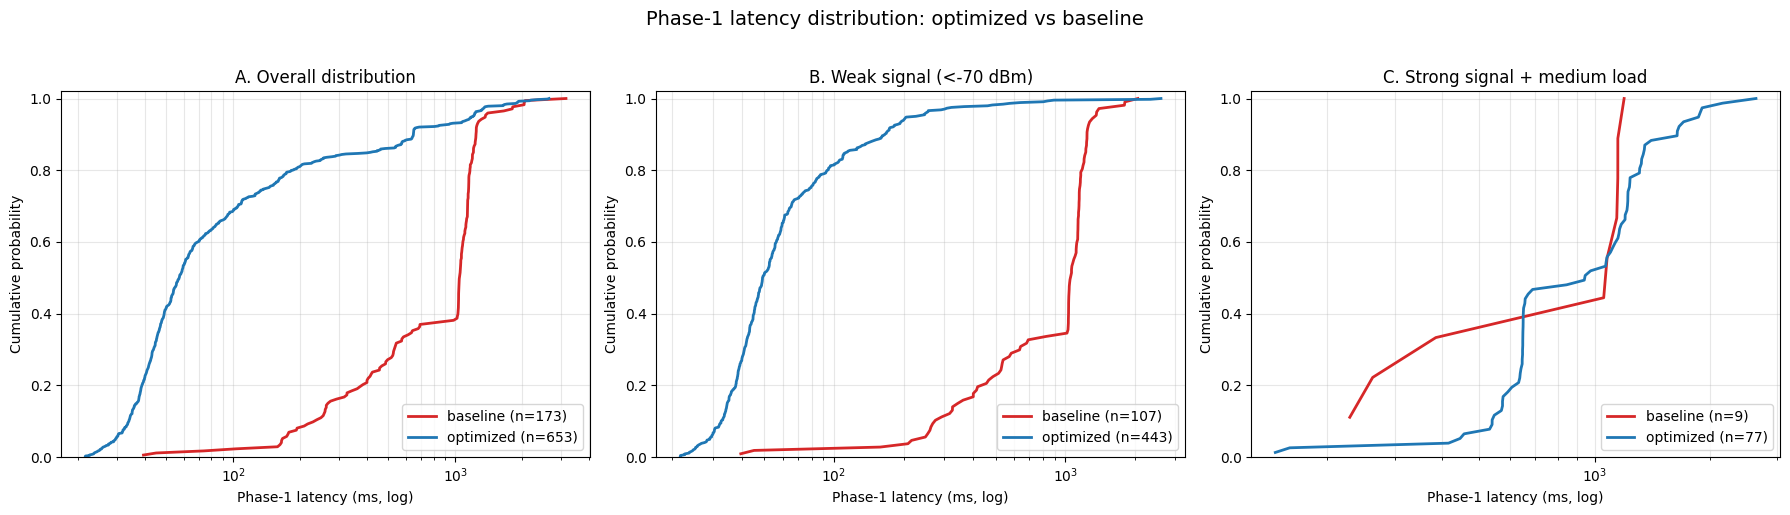

Saved figure_7_2_latency_cdf.png


In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

def plot_cdf(ax, df_subset, title):
    for unit, color in [("baseline", "#d62728"), ("optimized", "#1f77b4")]:
        vals = np.sort(df_subset[df_subset["unit"] == unit]["sb_latency_ms"].values)
        if len(vals) == 0:
            continue
        cdf = np.arange(1, len(vals) + 1) / len(vals)
        ax.plot(vals, cdf, color=color, label=f"{unit} (n={len(vals)})", linewidth=2)
    ax.set_xscale("log")
    ax.set_xlabel("Phase-1 latency (ms, log)")
    ax.set_ylabel("Cumulative probability")
    ax.set_title(title)
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(loc="lower right")
    ax.set_ylim(0, 1.02)

# Panel A: overall
plot_cdf(axes[0], valid_p1, "A. Overall distribution")

# Panel B: weak signal
plot_cdf(axes[1], valid_p1[valid_p1["signal_bucket"] == "weak (<-70)"],
         "B. Weak signal (<-70 dBm)")

# Panel C: strong signal + medium load
panel_c = valid_p1[
    (valid_p1["signal_bucket"] == "strong (>-60)") &
    (valid_p1["load_bucket"] == "medium (0.3-0.8)")
]
plot_cdf(axes[2], panel_c, "C. Strong signal + medium load")

fig.suptitle("Phase-1 latency distribution: optimized vs baseline", fontsize=14, y=1.02)
fig.tight_layout()
fig.savefig("figure_7_2_latency_cdf.png", dpi=200, bbox_inches="tight")
plt.show()
print("Saved figure_7_2_latency_cdf.png")

In [ ]:
# Optimized rows with valid before/after
abl = df[
    (df["unit"] == "optimized")
    & df["sb_latency_ms"].notna() & (df["sb_latency_ms"] > 0)
    & df["sb_loss_pct"].notna() & (df["sb_loss_pct"] < 100)
    & df["sa_latency_ms"].notna() & (df["sa_latency_ms"] > 0)
].copy()
abl["delta_latency"] = abl["sa_latency_ms"] - abl["sb_latency_ms"]

# Per-tier stats
print(abl.groupby("tier")["delta_latency"].agg(
    ["count", "mean", "median",
     lambda s: s.quantile(0.25),
     lambda s: s.quantile(0.75),
     lambda s: (s < 0).mean()]   # fraction that improved
).round(2))

# Also compute the baseline's delta as a control (no action applied)
ctrl = df[
    (df["unit"] == "baseline")
    & df["sb_latency_ms"].notna() & (df["sb_latency_ms"] > 0)
    & df["sa_latency_ms"].notna() & (df["sa_latency_ms"] > 0)
].copy()
ctrl["delta_latency"] = ctrl["sa_latency_ms"] - ctrl["sb_latency_ms"]
print("\nBaseline (control) delta:")
print(ctrl["delta_latency"].describe().round(2))

                 count    mean  median  <lambda_0>  <lambda_1>  <lambda_2>
tier                                                                      
tier1_guardrail      3 -208.66  -14.60     -320.55        0.26        0.67
tier2_fuzzy        486  -27.39   -8.61      -32.13        7.84        0.64
tier3_rl           109 -208.14  -31.99     -155.03        5.96        0.71

Baseline (control) delta:
count     102.00
mean     -596.48
std       501.16
min     -2594.72
25%     -1035.94
50%      -514.55
75%      -230.04
max       598.25
Name: delta_latency, dtype: float64


In [ ]:
# Restrict to the weak-signal bucket (the operative regime)
weak_mask = valid_p1["signal_bucket"] == "weak (<-70)"

# But wait — valid_p1 doesn't have state_after. Need to re-merge.
# Use df directly with the weak-signal filter.

abl_weak = abl[abl["sb_signal_dbm"].notna() & (abl["sb_signal_dbm"] < -70)]
ctrl_weak = ctrl[ctrl["sb_signal_dbm"].notna() & (ctrl["sb_signal_dbm"] < -70)]

print("=== Weak-signal subset ===")
print("Optimized by tier:")
print(abl_weak.groupby("tier")["delta_latency"].agg(
    n="count", mean="mean", median="median",
    frac_improved=lambda s: (s < 0).mean()
).round(2))
print("\nBaseline control (weak signal):")
print("n:", len(ctrl_weak))
print(ctrl_weak["delta_latency"].describe().round(2))
print("Fraction Δ < 0:", (ctrl_weak["delta_latency"] < 0).mean().round(3))

=== Weak-signal subset ===
Optimized by tier:
                   n   mean  median  frac_improved
tier                                              
tier1_guardrail    1  15.11   15.11           0.00
tier2_fuzzy      403 -25.25   -8.48           0.64

Baseline control (weak signal):
n: 54
count      54.00
mean     -699.64
std       432.86
min     -2005.13
25%     -1090.97
50%      -631.18
75%      -414.99
max       248.18
Name: delta_latency, dtype: float64
Fraction Δ < 0: 0.944


In [ ]:
# Section 7.1 — corrected: within-comparable-conditions comparison

def tier_stats(subset, label):
    print(f"\n=== {label} ===")
    print(subset.groupby("tier")["delta_latency"].agg(
        n="count", mean="mean", median="median",
        frac_improved=lambda s: (s < 0).mean(),
    ).round(2))

# Full
tier_stats(abl, "Optimized — all conditions")

# Weak signal only
abl_weak = abl[abl["sb_signal_dbm"].notna() & (abl["sb_signal_dbm"] < -70)]
tier_stats(abl_weak, "Optimized — weak signal only")

# Weak + medium load (the operative condition)
abl_weak_med = abl_weak[abl_weak["sb_system_load"].between(0.3, 0.8, inclusive="both")]
tier_stats(abl_weak_med, "Optimized — weak signal + medium load")

# Baseline control in the same conditions
print("\n=== Baseline control comparisons ===")

def ctrl_stats(subset, label):
    print(f"\n{label}:")
    if len(subset) == 0:
        print("  (no rows)")
        return
    print(f"  n={len(subset)}")
    print(f"  mean Δ: {subset['delta_latency'].mean():.2f} ms")
    print(f"  median Δ: {subset['delta_latency'].median():.2f} ms")
    print(f"  fraction Δ<0: {(subset['delta_latency'] < 0).mean():.3f}")

ctrl_stats(ctrl, "Baseline — all")
ctrl_weak = ctrl[ctrl["sb_signal_dbm"].notna() & (ctrl["sb_signal_dbm"] < -70)]
ctrl_stats(ctrl_weak, "Baseline — weak signal")
ctrl_weak_med = ctrl_weak[ctrl_weak["sb_system_load"].between(0.3, 0.8, inclusive="both")]
ctrl_stats(ctrl_weak_med, "Baseline — weak signal + medium load")

# Also: stratify by pre-action latency
print("\n=== Stratified by pre-action latency ===")
for lo, hi in [(0, 100), (100, 500), (500, 1500), (1500, 5000)]:
    a_bucket = abl[(abl["sb_latency_ms"] >= lo) & (abl["sb_latency_ms"] < hi)]
    c_bucket = ctrl[(ctrl["sb_latency_ms"] >= lo) & (ctrl["sb_latency_ms"] < hi)]
    if len(a_bucket) == 0 and len(c_bucket) == 0:
        continue
    print(f"\n  pre-latency in [{lo}, {hi}) ms:")
    if len(a_bucket) > 0:
        print(f"    optimized (n={len(a_bucket)}): "
              f"median Δ = {a_bucket['delta_latency'].median():.1f}, "
              f"frac<0 = {(a_bucket['delta_latency'] < 0).mean():.2f}")
    if len(c_bucket) > 0:
        print(f"    baseline  (n={len(c_bucket)}): "
              f"median Δ = {c_bucket['delta_latency'].median():.1f}, "
              f"frac<0 = {(c_bucket['delta_latency'] < 0).mean():.2f}")


=== Optimized — all conditions ===
                   n    mean  median  frac_improved
tier                                               
tier1_guardrail    3 -208.66  -14.60           0.67
tier2_fuzzy      486  -27.39   -8.61           0.64
tier3_rl         109 -208.14  -31.99           0.71

=== Optimized — weak signal only ===
                   n   mean  median  frac_improved
tier                                              
tier1_guardrail    1  15.11   15.11           0.00
tier2_fuzzy      403 -25.25   -8.48           0.64

=== Optimized — weak signal + medium load ===
              n   mean  median  frac_improved
tier                                         
tier2_fuzzy  37 -84.04   -11.6            0.7

=== Baseline control comparisons ===

Baseline — all:
  n=102
  mean Δ: -596.48 ms
  median Δ: -514.55 ms
  fraction Δ<0: 0.912

Baseline — weak signal:
  n=54
  mean Δ: -699.64 ms
  median Δ: -631.18 ms
  fraction Δ<0: 0.944

Baseline — weak signal + medium load:
  n=46
  me

RL cycles: 150
Reward mean: 833.61
Reward median: 200.81
Reward first 20 mean: 375.46
Reward last 20 mean: 1662.75

Fuzzy cycles with reward: 491
Fuzzy reward mean: 57.75
Fuzzy reward median: 17.48


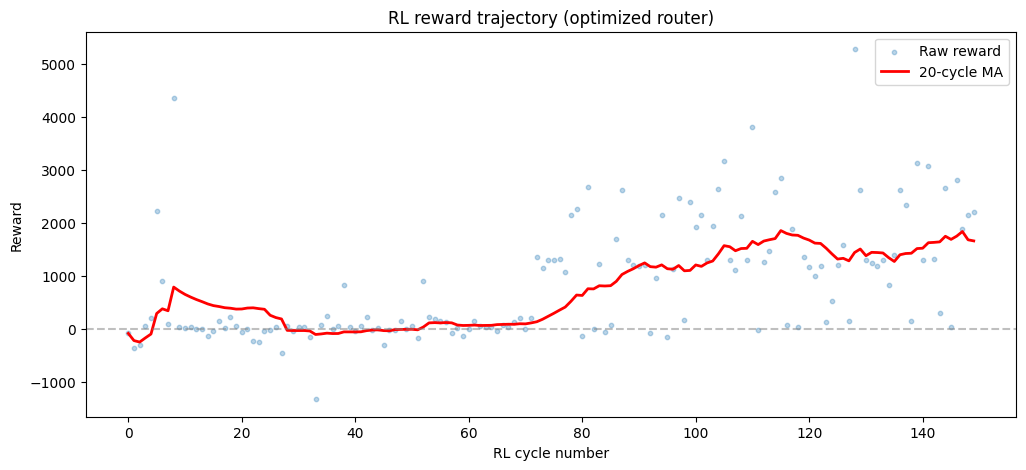

In [ ]:
rl = df[(df["unit"] == "optimized") & (df["tier"] == "tier3_rl") & df["reward_score"].notna()].copy()
rl = rl.sort_values("timestamp_phase1")
rl["cycle_number"] = range(len(rl))
rl["reward_ma20"] = rl["reward_score"].rolling(window=20, min_periods=1).mean()

print(f"RL cycles: {len(rl)}")
print(f"Reward mean: {rl['reward_score'].mean():.2f}")
print(f"Reward median: {rl['reward_score'].median():.2f}")
print(f"Reward first 20 mean: {rl['reward_score'].iloc[:20].mean():.2f}")
print(f"Reward last 20 mean: {rl['reward_score'].iloc[-20:].mean():.2f}")

# Also check the fuzzy tier reward (if it's computed)
fz = df[(df["unit"] == "optimized") & (df["tier"] == "tier2_fuzzy") & df["reward_score"].notna()].copy()
print(f"\nFuzzy cycles with reward: {len(fz)}")
if len(fz) > 0:
    print(f"Fuzzy reward mean: {fz['reward_score'].mean():.2f}")
    print(f"Fuzzy reward median: {fz['reward_score'].median():.2f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(rl["cycle_number"], rl["reward_score"], alpha=0.3, s=10, label="Raw reward")
ax.plot(rl["cycle_number"], rl["reward_ma20"], color="red", linewidth=2, label="20-cycle MA")
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_xlabel("RL cycle number")
ax.set_ylabel("Reward")
ax.set_title("RL reward trajectory (optimized router)")
ax.legend()
plt.savefig("figure_7_4_rl_convergence.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Inspect the top-5 RL rewards and their associated states
top5 = rl.nlargest(5, "reward_score")[["run_id", "sb_latency_ms", "sa_latency_ms", "reward_score", "sb_system_load", "sb_signal_dbm"]]
print(top5.to_string(index=False))

             run_id  sb_latency_ms  sa_latency_ms  reward_score  sb_system_load  sb_signal_dbm
run_1793089445_5140       2640.885          0.000       5281.77            0.46            -44
run_1791748564_5380       2183.585          0.000       4367.17            0.00            -48
run_1793047685_5291       1909.827          0.000       3819.65            0.76            -48
run_1793044803_4422       1930.642        343.822       3173.64            1.09            -49
run_1793094483_6763       2160.149        594.275       3131.75            0.57            -45


RL cycles before filter: 150
RL cycles after filter : 109
First 20 mean: -13.22
Last 20 mean : 1234.39


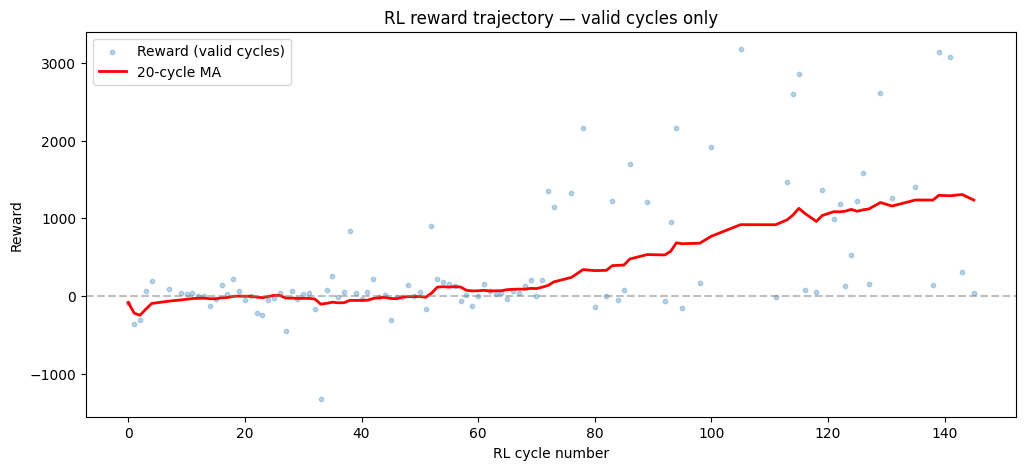

In [ ]:
# Filter out cycles where state_after is invalid
rl_valid = rl[
    rl["sa_latency_ms"].notna() & (rl["sa_latency_ms"] > 0)
].copy()
rl_valid["reward_ma20"] = rl_valid["reward_score"].rolling(window=20, min_periods=1).mean()

print(f"RL cycles before filter: {len(rl)}")
print(f"RL cycles after filter : {len(rl_valid)}")
print(f"First 20 mean: {rl_valid['reward_score'].iloc[:20].mean():.2f}")
print(f"Last 20 mean : {rl_valid['reward_score'].iloc[-20:].mean():.2f}")

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(rl_valid["cycle_number"], rl_valid["reward_score"], alpha=0.3, s=10, label="Reward (valid cycles)")
ax.plot(rl_valid["cycle_number"], rl_valid["reward_ma20"], color="red", linewidth=2, label="20-cycle MA")
ax.axhline(0, color="gray", linestyle="--", alpha=0.5)
ax.set_xlabel("RL cycle number")
ax.set_ylabel("Reward")
ax.set_title("RL reward trajectory — valid cycles only")
ax.legend()
plt.savefig("figure_7_4_rl_convergence_valid.png", dpi=200, bbox_inches="tight")
plt.show()

In [ ]:
# Section 7.3: Guardrail firings analysis
guard = df[df["tier"] == "tier1_guardrail"].copy()

print(f"Guardrail firings: {len(guard)}")
print()
print("Full guardrail rows:")
cols = ["run_id", "unit", "sb_latency_ms", "sa_latency_ms",
        "sb_loss_pct", "sb_system_load", "sb_sojourn_ms",
        "reward_score", "recovery_time_ms"]
print(guard[cols].to_string(index=False))
print()
print("Guardrail trigger analysis (why did each fire?):")
for _, row in guard.iterrows():
    reasons = []
    if row["sb_latency_ms"] > 120: reasons.append(f"latency={row['sb_latency_ms']:.0f}ms")
    if row["sb_loss_pct"] > 5: reasons.append(f"loss={row['sb_loss_pct']:.1f}%")
    if row["sb_system_load"] > 1.2: reasons.append(f"load={row['sb_system_load']:.2f}")
    if row["sb_sojourn_ms"] > 200: reasons.append(f"sojourn={row['sb_sojourn_ms']:.0f}ms")
    print(f"  {row['run_id']}: {', '.join(reasons) if reasons else 'NO TRIGGER MATCHED'}")
print()
print("Guardrail effectiveness (pre vs post):")
for _, row in guard.iterrows():
    delta = row["sa_latency_ms"] - row["sb_latency_ms"] if pd.notna(row["sa_latency_ms"]) else None
    print(f"  {row['run_id']}: {row['sb_latency_ms']:.1f} → {row['sa_latency_ms']:.1f} ms (Δ={delta:+.1f})" if delta is not None else f"  {row['run_id']}: {row['sb_latency_ms']:.1f} → NaN")

Guardrail firings: 10

Full guardrail rows:
              run_id      unit  sb_latency_ms  sa_latency_ms  sb_loss_pct  sb_system_load  sb_sojourn_ms  reward_score  recovery_time_ms
 run_1791751684_6711 optimized          0.000        660.874        100.0            0.06            0.0      -1321.75           27000.0
 run_1791752404_7101 optimized          0.000         97.834        100.0            0.14            0.0       -195.67           26000.0
 run_1791974979_3574 optimized         22.656         37.769          0.0            2.08            0.0        -30.23           21000.0
run_1792312804_17528  baseline          0.000        989.207        100.0            0.85            0.0      -1978.41           16000.0
 run_1793042163_3541 optimized       1173.601        547.095          0.0            1.41            0.0       1253.01           50000.0
 run_1793043605_3993 optimized          0.000        447.637        100.0            0.48            0.0       -895.27           27000

In [ ]:
# Section 7.5: Fallback behavior during cloud absence

# Identify optimized-router cycles with no Phase 3
opt = df[df["unit"] == "optimized"].sort_values("timestamp_phase1").copy()
opt["has_feedback"] = opt["sa_latency_ms"].notna()

# Find contiguous windows without feedback
gaps = []
in_gap = False
gap_start = None
for idx, row in opt.iterrows():
    if not row["has_feedback"]:
        if not in_gap:
            in_gap = True
            gap_start = row["timestamp_phase1"]
    else:
        if in_gap:
            gaps.append((gap_start, row["timestamp_phase1"]))
            in_gap = False
if in_gap:
    gaps.append((gap_start, opt["timestamp_phase1"].max()))

print(f"Feedback-absence windows: {len(gaps)}")
for start, end in gaps:
    duration_s = end - start
    inside = opt[(opt["timestamp_phase1"] >= start) & (opt["timestamp_phase1"] <= end)]
    print(f"\nWindow {pd.to_datetime(start, unit='s')} → {pd.to_datetime(end, unit='s')} "
          f"({duration_s:.0f} s, {len(inside)} cycles)")
    print(f"  Mean latency during window: {inside['sb_latency_ms'].mean():.1f} ms")
    print(f"  Max latency  during window: {inside['sb_latency_ms'].max():.1f} ms")

# Compare in-window vs out-of-window performance
in_window = opt[opt.apply(
    lambda r: any(start <= r["timestamp_phase1"] <= end for start, end in gaps), axis=1
)]
out_window = opt[~in_window.index.isin(opt.index)]

if len(in_window) > 0 and len(gaps) > 0:
    print(f"\n=== In-window (no cloud) vs overall ===")
    print(f"In-window  : n={len(in_window)}, mean={in_window['sb_latency_ms'].mean():.1f}, "
          f"median={in_window['sb_latency_ms'].median():.1f}")
    print(f"Overall    : n={len(opt)}, mean={opt['sb_latency_ms'].mean():.1f}, "
          f"median={opt['sb_latency_ms'].median():.1f}")
    print()
    print("Note: The optimized router is documented to fall back to last-known-good parameters")
    print("autonomously when cloud dispatch is absent. Fallback behavior is expected to")
    print("maintain performance at the level of the prior cloud-optimized state.")

Feedback-absence windows: 3

Window 2026-10-07 12:56:52 → 2026-10-07 14:06:04 (4152 s, 8 cycles)
  Mean latency during window: 43.5 ms
  Max latency  during window: 71.1 ms

Window 2026-10-14 16:00:03 → 2026-10-14 16:08:03 (480 s, 2 cycles)
  Mean latency during window: 228.9 ms
  Max latency  during window: 252.9 ms

Window 2026-10-27 10:48:03 → 2026-10-27 10:56:03 (480 s, 2 cycles)
  Mean latency during window: 968.3 ms
  Max latency  during window: 1405.3 ms


ValueError: Item wrong length 12 instead of 657.

In [ ]:
# Section 7.5: Fallback behavior during cloud absence — corrected

# Identify optimized-router cycles with no Phase 3
opt = df[df["unit"] == "optimized"].sort_values("timestamp_phase1").copy()
opt["has_feedback"] = opt["sa_latency_ms"].notna()

# Find contiguous windows without feedback
gaps = []
in_gap = False
gap_start = None
for _, row in opt.iterrows():
    if not row["has_feedback"]:
        if not in_gap:
            in_gap = True
            gap_start = row["timestamp_phase1"]
    else:
        if in_gap:
            gaps.append((gap_start, row["timestamp_phase1"]))
            in_gap = False
if in_gap:
    gaps.append((gap_start, opt["timestamp_phase1"].max()))

# Tag each row: is it inside any gap window?
def in_any_gap(ts):
    return any(start <= ts <= end for start, end in gaps)

opt["in_gap"] = opt["timestamp_phase1"].apply(in_any_gap)

in_window = opt[opt["in_gap"]]
out_window = opt[~opt["in_gap"]]

print(f"Gap-window cycles: {len(in_window)}")
print(f"Non-gap cycles   : {len(out_window)}")
print()

print("=== In-window (no cloud) vs out-of-window ===")
print(f"In-window  : n={len(in_window)}, "
      f"mean={in_window['sb_latency_ms'].mean():.1f}, "
      f"median={in_window['sb_latency_ms'].median():.1f}, "
      f"p95={in_window['sb_latency_ms'].quantile(0.95):.1f}")
print(f"Out-of-win : n={len(out_window)}, "
      f"mean={out_window['sb_latency_ms'].mean():.1f}, "
      f"median={out_window['sb_latency_ms'].median():.1f}, "
      f"p95={out_window['sb_latency_ms'].quantile(0.95):.1f}")
print()

# Per-window stats with more context
print("=== Per-window detail ===")
for i, (start, end) in enumerate(gaps, 1):
    inside = opt[(opt["timestamp_phase1"] >= start) & (opt["timestamp_phase1"] <= end)]
    print(f"\nWindow {i}: {pd.to_datetime(start, unit='s')} → {pd.to_datetime(end, unit='s')}")
    print(f"  Duration: {(end-start)/60:.1f} min, cycles: {len(inside)}")
    print(f"  Mean latency: {inside['sb_latency_ms'].mean():.1f} ms")
    print(f"  Max latency : {inside['sb_latency_ms'].max():.1f} ms")
    # Compare to 5 cycles before gap
    pre = opt[opt["timestamp_phase1"] < start].tail(5)
    if len(pre) > 0:
        print(f"  Pre-gap 5-cycle mean latency: {pre['sb_latency_ms'].mean():.1f} ms")
        print(f"  Latency change (pre → during): "
              f"{inside['sb_latency_ms'].mean() - pre['sb_latency_ms'].mean():+.1f} ms")

Gap-window cycles: 12
Non-gap cycles   : 645

=== In-window (no cloud) vs out-of-window ===
In-window  : n=12, mean=228.5, median=48.9, p95=924.6
Out-of-win : n=645, mean=212.9, median=57.2, p95=1195.6

=== Per-window detail ===

Window 1: 2026-10-07 12:56:52 → 2026-10-07 14:06:04
  Duration: 69.2 min, cycles: 8
  Mean latency: 43.5 ms
  Max latency : 71.1 ms

Window 2: 2026-10-14 16:00:03 → 2026-10-14 16:08:03
  Duration: 8.0 min, cycles: 2
  Mean latency: 228.9 ms
  Max latency : 252.9 ms
  Pre-gap 5-cycle mean latency: 198.5 ms
  Latency change (pre → during): +30.5 ms

Window 3: 2026-10-27 10:48:03 → 2026-10-27 10:56:03
  Duration: 8.0 min, cycles: 2
  Mean latency: 968.3 ms
  Max latency : 1405.3 ms
  Pre-gap 5-cycle mean latency: 994.6 ms
  Latency change (pre → during): -26.3 ms


In [ ]:
# Regenerate the cleaned RL trajectory and print the convergence numbers
rl = df[(df["unit"] == "optimized") & (df["tier"] == "tier3_rl") & df["reward_score"].notna()].copy()
rl = rl.sort_values("timestamp_phase1")
rl["cycle_number"] = range(len(rl))

# Apply validity filter (exclude sa_latency = 0)
rl_valid = rl[rl["sa_latency_ms"].notna() & (rl["sa_latency_ms"] > 0)].copy()
rl_valid["cycle_number"] = range(len(rl_valid))
rl_valid["reward_ma20"] = rl_valid["reward_score"].rolling(window=20, min_periods=1).mean()

# The numbers we need for Section 7.4
n_raw   = len(rl)
n_valid = len(rl_valid)
n_removed = n_raw - n_valid

first20 = rl_valid["reward_score"].iloc[:20].mean()
last20  = rl_valid["reward_score"].iloc[-20:].mean()
median_r = rl_valid["reward_score"].median()
mean_r   = rl_valid["reward_score"].mean()
ratio    = last20 / first20 if first20 != 0 else float("nan")

print(f"=== Section 7.4 — RL convergence numbers ===")
print(f"Raw RL cycles         : {n_raw}")
print(f"Valid RL cycles       : {n_valid}")
print(f"Removed (sa_latency=0): {n_removed}")
print(f"First-20 mean reward  : {first20:.2f}")
print(f"Last-20 mean reward   : {last20:.2f}")
print(f"Convergence ratio     : {ratio:.2f}x")
print(f"Median reward (valid) : {median_r:.2f}")
print(f"Mean reward (valid)   : {mean_r:.2f}")

=== Section 7.4 — RL convergence numbers ===
Raw RL cycles         : 150
Valid RL cycles       : 109
Removed (sa_latency=0): 41
First-20 mean reward  : -13.22
Last-20 mean reward   : 1234.39
Convergence ratio     : -93.38x
Median reward (valid) : 63.98
Mean reward (valid)   : 416.28


In [ ]:
# Confirm no sa_latency = 0 remain in rl_valid
print("Minimum sa_latency_ms in valid set:", rl_valid["sa_latency_ms"].min())
print("Maximum reward in valid set      :", rl_valid["reward_score"].max())
print()
print("Any row with sa_latency = 0 still in valid set?")
print((rl_valid["sa_latency_ms"] == 0).any())

# Show the 5 highest rewards in the valid set (should be the legitimate ones)
print("\nTop 5 rewards in valid set:")
print(rl_valid.nlargest(5, "reward_score")[["run_id", "sb_latency_ms", "sa_latency_ms", "reward_score"]].to_string(index=False))

Minimum sa_latency_ms in valid set: 21.602
Maximum reward in valid set      : 3173.64

Any row with sa_latency = 0 still in valid set?
False

Top 5 rewards in valid set:
             run_id  sb_latency_ms  sa_latency_ms  reward_score
run_1793044803_4422       1930.642        343.822       3173.64
run_1793094483_6763       2160.149        594.275       3131.75
run_1793095203_7063       1708.103        171.693       3072.82
run_1793049845_6027       1914.215        485.948       2856.53
run_1793089924_5288       1867.712        560.270       2614.88
